# Flight Summary Statistics

This notebook summarizes the analysis-ready flight data by shifted fiscal quarter and scheduled time of day. Shifted quarters are Q1 (December-February), Q2 (March-May), Q3 (June-August), and Q4 (September-November), with fiscal years labeled by their ending year. Time-of-day groups use scheduled departure hour: Morning (05:00-11:59), Afternoon (12:00-17:59), and Night (18:00-04:59). The cleaned dataset retains flights with a recorded arrival delay, so flight counts and delay statistics describe that analysis sample.

In [1]:
import pandas as pd

raw_flights = pd.read_csv("data/raw/flights.csv")
weather = pd.read_csv("data/raw/weather.csv")
airlines = pd.read_csv("data/raw/airlines.csv")
flights = pd.read_csv("data/cleaned/analysis_ready_flights.csv")

print(f"Raw flights: {raw_flights.shape}")
print(f"Weather: {weather.shape}")
print(f"Airlines: {airlines.shape}")
print(f"Analysis-ready flights: {flights.shape}")

print("\nRaw flights preview:")
display(raw_flights.head())
print("Weather preview:")
display(weather.head())
print("Airlines preview:")
display(airlines.head())

flights["quarter"] = ((flights["month"] % 12) // 3 + 1).astype(int)
flights["fiscal_year"] = (
    flights["year"].astype(int) + (flights["month"] == 12).astype(int)
)
flights["year_quarter"] = (
    "FY"
    + flights["fiscal_year"].astype(str)
    + " Q"
    + flights["quarter"].astype(str)
)

print("\nFiscal quarterly periods:", sorted(flights["year_quarter"].unique()))

Raw flights: (336776, 19)
Weather: (26115, 15)
Airlines: (16, 2)
Analysis-ready flights: (327346, 34)

Raw flights preview:


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


Weather preview:


,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib,time_hour
0,EWR,2013,1,1,1,39.02,26.06,59.37,270.0,10.35702,NaN,0.0,1012.0,10.0,2013-01-01T06:00:00Z
1,EWR,2013,1,1,2,39.02,26.96,61.63,250.0,8.05546,NaN,0.0,1012.3,10.0,2013-01-01T07:00:00Z
2,EWR,2013,1,1,3,39.02,28.04,64.43,240.0,11.50780,NaN,0.0,1012.5,10.0,2013-01-01T08:00:00Z
3,EWR,2013,1,1,4,39.92,28.04,62.21,250.0,12.65858,NaN,0.0,1012.2,10.0,2013-01-01T09:00:00Z
4,EWR,2013,1,1,5,39.02,28.04,64.43,260.0,12.65858,NaN,0.0,1011.9,10.0,2013-01-01T10:00:00Z


Airlines preview:


,carrier,name
0,9E,Endeavor Air Inc.
1,AA,American Airlines Inc.
2,AS,Alaska Airlines Inc.
3,B6,JetBlue Airways
4,DL,Delta Air Lines Inc.



Fiscal quarterly periods: ['FY2013 Q1', 'FY2013 Q2', 'FY2013 Q3', 'FY2013 Q4', 'FY2014 Q1']


### Load Data and Create Fiscal Quarters

In [2]:
quarterly_summary = (
    flights.groupby(["fiscal_year", "quarter"], as_index=False)
    .agg(
        flight_count=("arr_delay", "size"),
        mean_dep_delay_min=("dep_delay", "mean"),
        median_dep_delay_min=("dep_delay", "median"),
        mean_arr_delay_min=("arr_delay", "mean"),
        median_arr_delay_min=("arr_delay", "median"),
        pct_arrival_delay_over_15=(
            "arr_delay", lambda delay: delay.gt(15).mean() * 100
        ),
        mean_distance_miles=("distance", "mean"),
        mean_air_time_min=("air_time", "mean"),
        mean_visibility_miles=("visib", "mean"),
        mean_wind_speed_mph=("wind_speed", "mean"),
        mean_temperature_f=("temp", "mean"),
        mean_precipitation_inches=("precip", "mean"),
    )
)

quarterly_summary = quarterly_summary.round(2)

display(
    quarterly_summary.rename(
        columns=lambda column: column.replace("_", " ").upper()
    )
)

assert quarterly_summary["flight_count"].sum() == len(flights)
assert quarterly_summary["quarter"].between(1, 4).all()
assert flights.loc[flights["month"] == 12, "quarter"].eq(1).all()
print("Shifted quarterly summary validation passed.")

,FISCAL YEAR,QUARTER,FLIGHT COUNT,MEAN DEP DELAY MIN,MEDIAN DEP DELAY MIN,MEAN ARR DELAY MIN,MEDIAN ARR DELAY MIN,PCT ARRIVAL DELAY OVER 15,MEAN DISTANCE MILES,MEAN AIR TIME MIN,MEAN VISIBILITY MILES,MEAN WIND SPEED MPH,MEAN TEMPERATURE F,MEAN PRECIPITATION INCHES
0,2013,1,50009,10.35,-2.0,5.89,-3.0,22.83,1010.70,152.85,8.84,11.89,36.11,0.00
1,2013,2,83594,13.30,-2.0,6.81,-5.0,24.23,1039.76,149.28,9.26,12.01,52.81,0.00
2,2013,3,84124,18.21,0.0,12.99,-3.0,28.64,1071.21,148.38,9.53,10.29,77.18,0.01
3,2013,4,82599,6.10,-3.0,-1.22,-9.0,15.80,1047.49,149.26,9.58,10.67,58.98,0.00
4,2014,1,27020,16.48,0.0,14.87,2.0,32.61,1076.33,162.59,8.56,10.16,39.43,0.01


Shifted quarterly summary validation passed.


### Summarize Flight Data by Fiscal Quarter

## Summary by Scheduled Time of Day

Flights are grouped by scheduled departure hour: Morning (05:00-11:59), Afternoon (12:00-17:59), and Night (18:00-04:59).

In [3]:
import numpy as np

scheduled_hour = flights["scheduled_hour"]
flights["time_of_day"] = pd.Categorical(
    np.select(
        [scheduled_hour.between(5, 11), scheduled_hour.between(12, 17)],
        ["Morning", "Afternoon"],
        default="Night",
    ),
    categories=["Morning", "Afternoon", "Night"],
    ordered=True,
)

time_of_day_summary = (
    flights.groupby("time_of_day", as_index=False, observed=True)
    .agg(
        flight_count=("arr_delay", "size"),
        mean_dep_delay_min=("dep_delay", "mean"),
        median_dep_delay_min=("dep_delay", "median"),
        mean_arr_delay_min=("arr_delay", "mean"),
        median_arr_delay_min=("arr_delay", "median"),
        pct_arrival_delay_over_15=(
            "arr_delay", lambda delay: delay.gt(15).mean() * 100
        ),
        mean_distance_miles=("distance", "mean"),
        mean_air_time_min=("air_time", "mean"),
        mean_visibility_miles=("visib", "mean"),
        mean_wind_speed_mph=("wind_speed", "mean"),
        mean_temperature_f=("temp", "mean"),
        mean_precipitation_inches=("precip", "mean"),
    )
)

time_of_day_summary = time_of_day_summary.round(2)

display(
    time_of_day_summary.rename(
        columns=lambda column: column.replace("_", " ").upper()
    )
)

assert flights["scheduled_hour"].between(0, 23).all()
assert time_of_day_summary["flight_count"].sum() == len(flights)
print("Time-of-day summary validation passed.")

,TIME OF DAY,FLIGHT COUNT,MEAN DEP DELAY MIN,MEDIAN DEP DELAY MIN,MEAN ARR DELAY MIN,MEDIAN ARR DELAY MIN,PCT ARRIVAL DELAY OVER 15,MEAN DISTANCE MILES,MEAN AIR TIME MIN,MEAN VISIBILITY MILES,MEAN WIND SPEED MPH,MEAN TEMPERATURE F,MEAN PRECIPITATION INCHES
0,Morning,128586,3.91,-3.0,-1.82,-8.0,14.61,1069.54,153.13,9.11,9.99,54.50,0.0
1,Afternoon,127017,15.38,0.0,10.43,-3.0,27.09,1033.22,149.83,9.40,12.22,59.96,0.0
2,Night,71743,23.04,1.0,16.27,0.0,34.06,1037.26,147.83,9.42,10.92,56.27,0.0


Time-of-day summary validation passed.


### Group Flights by Scheduled Time of Day

## Seasonal Arrival Delay ANOVA

Test whether mean arrival delay differs across Winter, Spring, Summer, and Fall. The null hypothesis is that all four seasonal means are equal; Welch's one-way ANOVA is used so equal variances are not required.

In [4]:
from scipy import stats
import numpy as np
from itertools import combinations

season_order = ["Winter", "Spring", "Summer", "Fall"]
seasonal_groups = [
    flights.loc[flights["season"] == season, "arr_delay"].dropna()
    for season in season_order
]

seasonal_anova_summary = (
    flights.groupby("season", observed=True)["arr_delay"]
    .agg(
        flight_count="count",
        mean_delay_min="mean",
        std_delay_min="std",
        min_delay_min="min",
        q1_delay_min=lambda values: values.quantile(0.25),
        median_delay_min="median",
        q3_delay_min=lambda values: values.quantile(0.75),
        max_delay_min="max",
    )
    .reindex(season_order)
)
seasonal_anova_summary["iqr_delay_min"] = (
    seasonal_anova_summary["q3_delay_min"]
    - seasonal_anova_summary["q1_delay_min"]
)
seasonal_anova_summary = seasonal_anova_summary.round(2)

print("Arrival delay by season (minutes)")
display(seasonal_anova_summary)

if seasonal_anova_summary["flight_count"].isna().any():
    raise ValueError("Every season must have observations for the ANOVA.")
if (seasonal_anova_summary["flight_count"] < 2).any():
    raise ValueError("Each season needs at least two observations for the ANOVA.")

# Assumption 1: observations and seasonal groups are independent.
print("Independence: assess using study design; independence is not directly testable from these values.")

# Assumption 2: no serious violation of normality in the seasonal distributions.
seasonal_residuals = pd.concat([
    group - group.mean()
    for group in seasonal_groups
], ignore_index=True)
normality_sample = seasonal_residuals.sample(
    n=min(5000, len(seasonal_residuals)), random_state=42
)
normality_test = stats.normaltest(normality_sample)
print(
    "Normality screening (D'Agostino test on a reproducible 5,000-value residual sample): "
    f"statistic={normality_test.statistic:.4f}, p={normality_test.pvalue:.6g}"
)

# Assumption check for equal population variances.
variance_test = stats.levene(*seasonal_groups, center="median")
print(
    "Levene test for equal variances: "
    f"statistic={variance_test.statistic:.4f}, p={variance_test.pvalue:.6g}"
)

welch_anova = stats.f_oneway(*seasonal_groups, equal_var=False)
print(f"Welch's ANOVA F-statistic: {welch_anova.statistic:.4f}")
p_value_display = (
    "< 1e-300" if welch_anova.pvalue == 0 else f"{welch_anova.pvalue:.6g}"
)
print(f"p-value: {p_value_display}")

# Effect size: eta squared (SS between / SS total).
all_delays = pd.concat(seasonal_groups, ignore_index=True)
grand_mean = all_delays.mean()
ss_between = sum(
    len(group) * (group.mean() - grand_mean) ** 2
    for group in seasonal_groups
)
ss_total = ((all_delays - grand_mean) ** 2).sum()
eta_squared = ss_between / ss_total
print(f"Eta squared (η²): {eta_squared:.4f}")
if eta_squared < 0.01:
    effect_label = "negligible"
elif eta_squared < 0.06:
    effect_label = "small"
elif eta_squared < 0.14:
    effect_label = "medium"
else:
    effect_label = "large"
print(f"Effect-size interpretation: {effect_label} season effect")

alpha = 0.05
if welch_anova.pvalue < alpha:
    print("Conclusion: reject the null hypothesis; mean arrival delay differs by season.")
else:
    print("Conclusion: insufficient evidence that mean arrival delay differs by season.")

# Pairwise comparisons using Welch's unequal-variance t-test.
# Bonferroni adjustment is applied across all six seasonal pairings.
comparison_rows = []

for season_a, season_b in combinations(season_order, 2):
    group_a = flights.loc[flights["season"] == season_a, "arr_delay"].dropna()
    group_b = flights.loc[flights["season"] == season_b, "arr_delay"].dropna()

    pairwise_test = stats.ttest_ind(group_a, group_b, equal_var=False)
    raw_p = pairwise_test.pvalue
    adjusted_p = min(raw_p * 6, 1.0)

    mean_difference = group_a.mean() - group_b.mean()
    variance_a = group_a.var(ddof=1) / len(group_a)
    variance_b = group_b.var(ddof=1) / len(group_b)
    standard_error = np.sqrt(variance_a + variance_b)
    degrees_freedom = (
        (variance_a + variance_b) ** 2
        / ((variance_a ** 2) / (len(group_a) - 1)
           + (variance_b ** 2) / (len(group_b) - 1))
    )
    critical_value = stats.t.ppf(1 - alpha / 12, degrees_freedom)
    ci_lower = mean_difference - critical_value * standard_error
    ci_upper = mean_difference + critical_value * standard_error

    comparison_rows.append({
        "comparison": f"{season_a} vs {season_b}",
        "mean_difference_min": mean_difference,
        "ci_95_low_min": ci_lower,
        "ci_95_high_min": ci_upper,
        "t_statistic": pairwise_test.statistic,
        "raw_p_value": raw_p,
        "bonferroni_p_value": adjusted_p,
        "significant_alpha_0.05": adjusted_p < alpha,
    })

pairwise_comparisons = pd.DataFrame(comparison_rows).round(6)
print("\nPairwise Welch t-tests (Bonferroni-adjusted across 6 comparisons)")
display(pairwise_comparisons)

Arrival delay by season (minutes)


,flight_count,mean_delay_min,std_delay_min,min_delay_min,q1_delay_min,median_delay_min,q3_delay_min,max_delay_min,iqr_delay_min
season,,,,,,,,,
Winter,77029,9.04,42.47,-70.0,-14.0,-2.0,17.0,1272.0,31.0
Spring,83594,6.81,45.41,-86.0,-18.0,-5.0,14.0,931.0,32.0
Summer,84124,12.99,52.50,-68.0,-16.0,-3.0,21.0,1127.0,37.0
Fall,82599,-1.22,34.79,-68.0,-19.0,-9.0,5.0,1007.0,24.0


Independence: assess using study design; independence is not directly testable from these values.
Normality screening (D'Agostino test on a reproducible 5,000-value residual sample): statistic=3728.6719, p=0
Levene test for equal variances: statistic=1269.4192, p=0
Welch's ANOVA F-statistic: 1798.1750
p-value: < 1e-300
Eta squared (η²): 0.0137
Effect-size interpretation: small season effect
Conclusion: reject the null hypothesis; mean arrival delay differs by season.

Pairwise Welch t-tests (Bonferroni-adjusted across 6 comparisons)


,comparison,mean_difference_min,ci_95_low_min,ci_95_high_min,t_statistic,raw_p_value,bonferroni_p_value,significant_alpha_0.05
0,Winter vs Spring,2.228902,1.650363,2.807440,10.164387,0.0,0.0,True
1,Winter vs Summer,-3.952313,-4.577676,-3.326950,-16.674076,0.0,0.0,True
2,Winter vs Fall,10.258690,9.743895,10.773485,52.575159,0.0,0.0,True
3,Spring vs Summer,-6.181214,-6.813494,-5.548934,-25.792107,0.0,0.0,True
4,Spring vs Fall,8.029789,7.506613,8.552964,40.492924,0.0,0.0,True
5,Summer vs Fall,14.211003,13.636472,14.785534,65.258120,0.0,0.0,True


### Run Welch's ANOVA and Interpret the Result

`stats.f_oneway(*seasonal_groups, equal_var=False)` runs Welch's one-way ANOVA. The test compares variation among seasonal means with variation within seasons. The F-statistic and p-value test the null hypothesis that all four seasonal population means are equal against the alternative that at least one mean differs.

The code uses a significance level of 0.05. Eta squared (`η²`) reports the proportion of total variation explained by season. Conventional labels describe η² as negligible below 0.01, small below 0.06, medium below 0.14, and large at 0.14 or higher. Eta squared is descriptive and does not identify which seasonal means differ.

### Add Pairwise Seasonal Comparisons

The pairwise section uses Welch's unequal-variance t-test for each of the six possible season pairs. For every comparison, the output reports the mean difference, 95% confidence interval, t-statistic, raw p-value, and Bonferroni-adjusted p-value. The Bonferroni adjustment multiplies each raw p-value by six, reducing the chance of false-positive findings across the full set of comparisons.

A Bonferroni-adjusted p-value below 0.05 or a confidence interval that excludes zero identifies a statistically significant pairwise difference. These comparisons should be used to explain where the overall seasonal difference occurs.

### Prepare Seasonal Groups and Descriptive Statistics

`season_order` fixes the display order, and `seasonal_groups` filters `arr_delay` separately for each season. `dropna()` removes missing delays. The summary table reports every season's sample size, mean, standard deviation, minimum, quartiles, median, maximum, and IQR, providing a direct view of central tendency and variability.

The independence of observations must be checked from the study design. The code also screens residual normality with a reproducible sample and D'Agostino's test. Because very large samples can make small departures statistically significant, the normal probability plot should be viewed alongside the test. A median-centered Levene test checks whether seasonal variances differ; Welch's ANOVA remains appropriate if they do.

The final group table must contain at least two observations per season. The code raises an error if a season is missing or too small for the test.

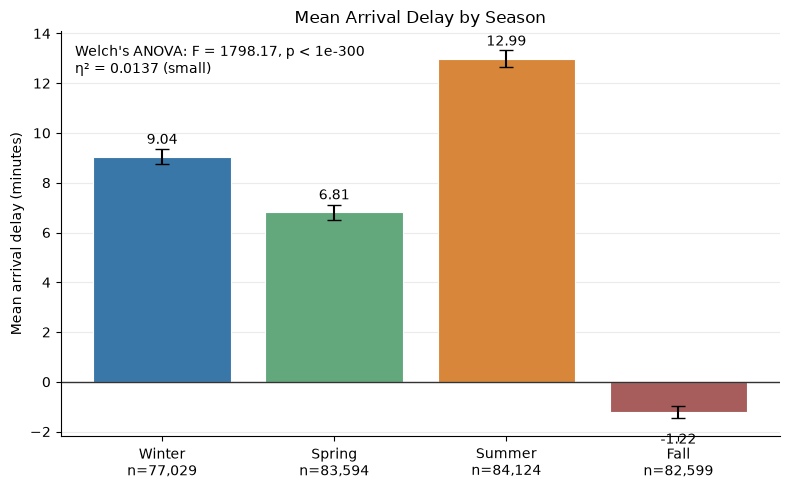

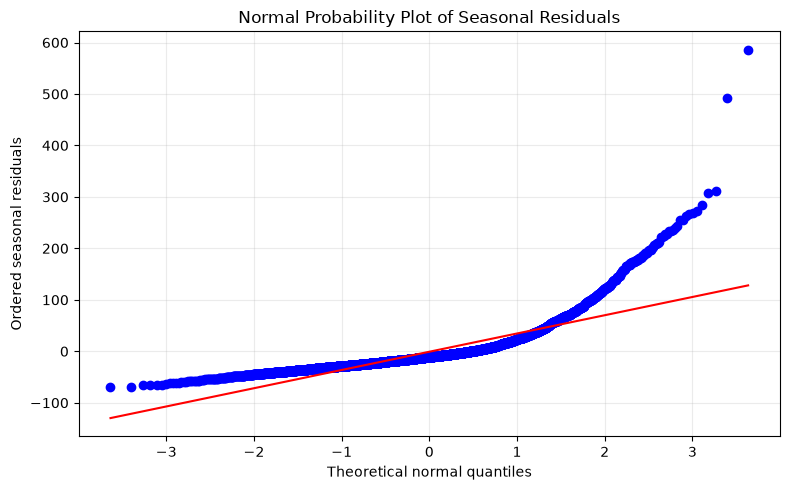

In [5]:
import matplotlib.pyplot as plt
from math import sqrt

plot_summary = seasonal_anova_summary.copy()
plot_summary["ci_95"] = [
    stats.t.ppf(0.975, count - 1) * delay_std / sqrt(count)
    for count, delay_std in zip(
        plot_summary["flight_count"], plot_summary["std_delay_min"]
    )
]

fig, ax = plt.subplots(figsize=(8, 5))
season_colors = ["#3977A8", "#62A87C", "#D8873A", "#A85D5D"]
bars = ax.bar(
    season_order,
    plot_summary["mean_delay_min"],
    yerr=plot_summary["ci_95"],
    capsize=5,
    color=season_colors,
    edgecolor="white",
    linewidth=0.8,
)

ax.axhline(0, color="#333333", linewidth=1)
ax.set_xticks(
    range(len(season_order)),
    [
        f"{season}\nn={int(count):,}"
        for season, count in zip(season_order, plot_summary["flight_count"])
    ],
)
ax.set_ylabel("Mean arrival delay (minutes)")
ax.set_title("Mean Arrival Delay by Season")
ax.text(
    0.02,
    0.97,
    f"Welch's ANOVA: F = {welch_anova.statistic:.2f}, p {p_value_display}\nη² = {eta_squared:.4f} ({effect_label})",
    transform=ax.transAxes,
    ha="left",
    va="top",
)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

for bar, mean_delay in zip(bars, plot_summary["mean_delay_min"]):
    ax.annotate(
        f"{mean_delay:.2f}",
        (bar.get_x() + bar.get_width() / 2, mean_delay),
        xytext=(0, 7 if mean_delay >= 0 else -15),
        textcoords="offset points",
        ha="center",
        va="bottom" if mean_delay >= 0 else "top",
    )

fig.tight_layout()
plt.show()

# Normal probability plot for checking the approximate-normality assumption.
fig, ax = plt.subplots(figsize=(8, 5))
stats.probplot(normality_sample, dist="norm", plot=ax)
ax.set_title("Normal Probability Plot of Seasonal Residuals")
ax.set_xlabel("Theoretical normal quantiles")
ax.set_ylabel("Ordered seasonal residuals")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Calculate Confidence Intervals and Create the Bar Chart

### Interpretation of the Results

The graph shows the average arrival delay for each season, with 95% confidence intervals and seasonal sample sizes. The summary table also reports standard deviations and IQR values, so both sample size and variability are visible when comparing the seasons.

Welch's ANOVA tests whether the seasonal population means are equal. It provides an F-statistic and p-value, and eta squared (`η²`) summarizes the proportion of total arrival-delay variation associated with season. A statistically significant result indicates at least one seasonal mean differs, but it does not identify which seasons differ; pairwise tests would be needed for that conclusion.

The assumption check distinguishes study-design independence from statistical diagnostics. Independence should be evaluated from how flights were collected. Residual normality is screened using a normal probability plot and a reproducible D'Agostino test; for very large samples, graphical results may be more informative because tests become sensitive to small departures. Levene's test reports whether variances differ. Welch's ANOVA does not require equal variances, and large seasonal sample sizes make it robust to moderate non-normality.